In [3]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns
import warnings
from datetime import datetime
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

#configuration
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

#Set figure size defaults\
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10

print("Libraries imported successfully!")


Libraries imported successfully!


In [4]:
# File paths - UPDATE THESE TO YOUR LOCAL PATHS
collisions_path = 'collisions.csv'
vehicles_path = 'vehicles.csv'
casualties_path = 'casualties.csv'

# Load datasets
print("Loading datasets...")
try:
    collisions_df = pd.read_csv(collisions_path, low_memory=False)
    vehicles_df = pd.read_csv(vehicles_path, low_memory=False)
    casualties_df = pd.read_csv(casualties_path, low_memory=False)
    print("✓ All datasets loaded successfully!")
except FileNotFoundError as e:
    print(f"Error: {e}")
    print("Please update the file paths in the cell above.")

Loading datasets...
✓ All datasets loaded successfully!


In [5]:
# Display basic information about each dataset
print("="*80)
print("COLLISIONS DATASET")
print("="*80)
print(f"Shape: {collisions_df.shape}")
print(f"Columns: {collisions_df.columns.tolist()[:10]}...")
print("\n" + "="*80)
print("VEHICLES DATASET")
print("="*80)
print(f"Shape: {vehicles_df.shape}")
print(f"Columns: {vehicles_df.columns.tolist()[:10]}...")
print("\n" + "="*80)
print("CASUALTIES DATASET")
print("="*80)
print(f"Shape: {casualties_df.shape}")
print(f"Columns: {casualties_df.columns.tolist()[:10]}...")

COLLISIONS DATASET
Shape: (100927, 44)
Columns: ['collision_index', 'collision_year', 'collision_ref_no', 'location_easting_osgr', 'location_northing_osgr', 'longitude', 'latitude', 'police_force', 'collision_severity', 'number_of_vehicles']...

VEHICLES DATASET
Shape: (183514, 32)
Columns: ['collision_index', 'collision_year', 'collision_ref_no', 'vehicle_reference', 'vehicle_type', 'towing_and_articulation', 'vehicle_manoeuvre_historic', 'vehicle_manoeuvre', 'vehicle_direction_from', 'vehicle_direction_to']...

CASUALTIES DATASET
Shape: (128272, 23)
Columns: ['collision_index', 'collision_year', 'collision_ref_no', 'vehicle_reference', 'casualty_reference', 'casualty_class', 'sex_of_casualty', 'age_of_casualty', 'age_band_of_casualty', 'casualty_severity']...


In [6]:
# Display first few rows of each dataset
print("COLLISIONS - First 5 rows:")
display(collisions_df.head())

print("\nVEHICLES - First 5 rows:")
display(vehicles_df.head())

print("\nCASUALTIES - First 5 rows:")
display(casualties_df.head())

COLLISIONS - First 5 rows:


,collision_index,collision_year,collision_ref_no,location_easting_osgr,location_northing_osgr,longitude,latitude,police_force,collision_severity,number_of_vehicles,number_of_casualties,date,day_of_week,time,local_authority_district,local_authority_ons_district,local_authority_highway,local_authority_highway_current,first_road_class,first_road_number,road_type,speed_limit,junction_detail_historic,junction_detail,junction_control,second_road_class,second_road_number,pedestrian_crossing_human_control_historic,pedestrian_crossing_physical_facilities_historic,pedestrian_crossing,light_conditions,weather_conditions,road_surface_conditions,special_conditions_at_site,carriageway_hazards_historic,carriageway_hazards,urban_or_rural_area,did_police_officer_attend_scene_of_accident,trunk_road_flag,lsoa_of_accident_location,enhanced_severity_collision,collision_injury_based,collision_adjusted_severity_serious,collision_adjusted_severity_slight
0,202417M119024,2024,17M119024,450057,519938,-1.22722,54.57219,17,3,2,1,05/12/2024,5,16:10,-1,E06000002,E06000002,E06000002,6,0,6,30,-1,0,-1,-1,-1,-1,-1,0,4,2,2,-1,-1,0,1,3,2,E01035190,3,1,0.000000,1.000000
1,202417S312124,2024,17S312124,445858,516830,-1.29265,54.54466,17,3,1,1,22/10/2024,3,14:56,-1,E06000004,E06000004,E06000004,6,0,6,30,-1,0,-1,-1,-1,-1,-1,0,1,1,1,-1,-1,0,1,3,2,E01012239,3,1,0.000000,1.000000
2,2024070110901,2024,070110901,364765,390979,-2.53157,53.41443,7,3,2,1,24/01/2024,4,17:50,-1,E06000007,E06000007,E06000007,6,0,6,30,3,13,4,6,0,0,0,0,4,1,1,0,0,0,2,2,2,E01012459,-1,0,0.014743,0.985257
3,2024041446676,2024,041446676,365989,419804,-2.51630,53.67359,4,2,1,1,22/05/2024,4,17:45,-1,E06000008,E06000008,E06000008,3,675,6,50,-1,0,-1,-1,-1,-1,-1,0,1,5,5,-1,-1,0,2,1,2,E01012628,6,1,1.000000,0.000000
4,2024041478641,2024,041478641,366864,430071,-2.50416,53.76592,4,2,2,1,11/08/2024,1,15:36,-1,E06000008,E06000008,E06000008,3,6119,3,50,-1,16,4,6,0,-1,-1,0,1,1,1,-1,-1,0,1,1,2,E01012581,7,1,1.000000,0.000000



VEHICLES - First 5 rows:


,collision_index,collision_year,collision_ref_no,vehicle_reference,vehicle_type,towing_and_articulation,vehicle_manoeuvre_historic,vehicle_manoeuvre,vehicle_direction_from,vehicle_direction_to,vehicle_location_restricted_lane_historic,vehicle_location_restricted_lane,junction_location,skidding_and_overturning,hit_object_in_carriageway,vehicle_leaving_carriageway,hit_object_off_carriageway,first_point_of_impact,vehicle_left_hand_drive,journey_purpose_of_driver_historic,journey_purpose_of_driver,sex_of_driver,age_of_driver,age_band_of_driver,engine_capacity_cc,propulsion_code,age_of_vehicle,generic_make_model,driver_imd_decile,lsoa_of_driver,escooter_flag,driver_distance_banding
0,2024471526976,2024,471526976,2,4,0,-1,19,4,8,-1,0,8,0,0,0,0,3,1,-1,9,1,23,5,234,1,16,MAKE AND MODEL REDACTED,8,E01020954,0,1
1,2024471493223,2024,471493223,2,9,0,-1,2,0,0,-1,0,0,0,0,0,0,1,1,-1,6,-1,-1,-1,2198,1,15,MAKE AND MODEL REDACTED,-1,-1,0,-1
2,2024010504128,2024,010504128,2,9,0,2,2,0,0,0,0,0,0,0,0,0,2,1,6,6,3,-1,-1,2198,1,18,MAKE AND MODEL REDACTED,-1,-1,0,-1
3,2024302400896,2024,302400896,2,9,0,18,19,1,4,0,0,0,0,0,0,0,1,1,6,6,1,56,9,6496,1,0,MAKE AND MODEL REDACTED,5,E01019782,0,2
4,2024631472488,2024,631472488,2,90,0,-1,19,7,3,-1,0,8,0,0,0,0,4,1,-1,9,1,55,8,2184,2,0,MAKE AND MODEL REDACTED,7,W01000623,0,4



CASUALTIES - First 5 rows:


,collision_index,collision_year,collision_ref_no,vehicle_reference,casualty_reference,casualty_class,sex_of_casualty,age_of_casualty,age_band_of_casualty,casualty_severity,pedestrian_location,pedestrian_movement,car_passenger,bus_or_coach_passenger,pedestrian_road_maintenance_worker,casualty_type,casualty_imd_decile,lsoa_of_casualty,enhanced_casualty_severity,casualty_injury_based,casualty_adjusted_severity_serious,casualty_adjusted_severity_slight,casualty_distance_banding
0,2024991534042,2024,991534042,1,1,3,2,39,7,3,1,3,0,0,-1,0,-1,-1,3,1,0.00000,1.00000,-1
1,2024430342145,2024,430342145,2,1,1,2,25,5,3,0,0,0,0,0,1,4,E01028532,-1,0,0.02417,0.97583,1
2,2024471442093,2024,471442093,2,1,1,1,49,8,3,0,0,0,0,0,1,8,E01031491,3,1,0.00000,1.00000,1
3,2024101511084,2024,101511084,1,1,1,2,39,7,3,0,0,0,0,0,9,1,E01008859,3,1,0.00000,1.00000,1
4,2024161531062,2024,161531062,1,1,1,1,59,9,3,0,0,0,0,0,1,5,E01012902,3,1,0.00000,1.00000,1


In [7]:
# Data types and info
print("COLLISIONS Dataset Info:")
collisions_df.info()

print("\n" + "="*80 + "\n")
print("VEHICLES Dataset Info:")
vehicles_df.info()

print("\n" + "="*80 + "\n")
print("CASUALTIES Dataset Info:")
casualties_df.info()

COLLISIONS Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100927 entries, 0 to 100926
Data columns (total 44 columns):
 #   Column                                            Non-Null Count   Dtype  
---  ------                                            --------------   -----  
 0   collision_index                                   100927 non-null  object 
 1   collision_year                                    100927 non-null  int64  
 2   collision_ref_no                                  100927 non-null  object 
 3   location_easting_osgr                             100927 non-null  int64  
 4   location_northing_osgr                            100927 non-null  int64  
 5   longitude                                         100927 non-null  float64
 6   latitude                                          100927 non-null  float64
 7   police_force                                      100927 non-null  int64  
 8   collision_severity                                100927 no

In [11]:
# Function to analyze missing values
def analyze_missing_values(df, dataset_name):
    print(f"\n{'='*80}")
    print(f"Missing Values Analysis - {dataset_name}")
    print(f"{'='*80}")
    
    missing_stats = pd.DataFrame({
        'Column': df.columns,
        'Missing_Count': df.isnull().sum().values,
        'Missing_Percentage': (df.isnull().sum().values / len(df) * 100).round(2)
    })
    
    missing_stats = missing_stats[missing_stats['Missing_Count'] > 0].sort_values(
        'Missing_Percentage', ascending=False
    )
    
    if len(missing_stats) == 0:
        print("No missing values found")
    else:
        print(f"Found {len(missing_stats)} columns with missing values:\n")
        display(missing_stats)
    
    return missing_stats

# Analyze missing values in all datasets
collisions_missing = analyze_missing_values(collisions_df, "COLLISIONS")
vehicles_missing = analyze_missing_values(vehicles_df, "VEHICLES")
casualties_missing = analyze_missing_values(casualties_df, "CASUALTIES")


Missing Values Analysis - COLLISIONS
Found 1 columns with missing values:



,Column,Missing_Count,Missing_Percentage
17,local_authority_highway_current,3,0.0



Missing Values Analysis - VEHICLES
No missing values found

Missing Values Analysis - CASUALTIES
No missing values found


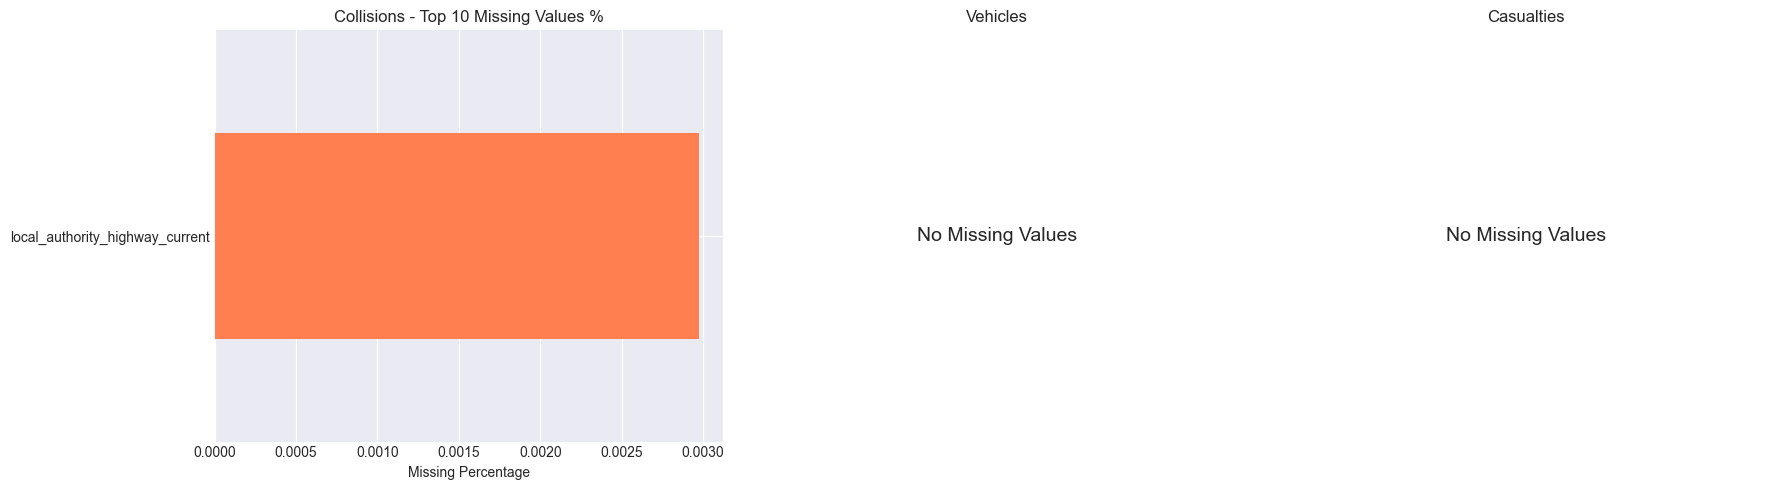

In [12]:
# Visualize missing values
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

datasets = [
    (collisions_df, 'Collisions', axes[0]),
    (vehicles_df, 'Vehicles', axes[1]),
    (casualties_df, 'Casualties', axes[2])
]

for df, name, ax in datasets:
    missing_pct = (df.isnull().sum() / len(df) * 100)
    missing_pct = missing_pct[missing_pct > 0].sort_values(ascending=True)
    
    if len(missing_pct) > 0:
        missing_pct.tail(10).plot(kind='barh', ax=ax, color='coral')
        ax.set_title(f'{name} - Top 10 Missing Values %')
        ax.set_xlabel('Missing Percentage')
    else:
        ax.text(0.5, 0.5, 'No Missing Values', 
                ha='center', va='center', fontsize=14)
        ax.set_title(f'{name}')
        ax.axis('off')

plt.tight_layout()
plt.show()

In [13]:
# Identify and convert date/time columns
print("Converting date/time columns...\n")

# Common date column names in DfT data
date_columns = ['date', 'accident_date', 'Date']
time_columns = ['time', 'accident_time', 'Time']

for col in collisions_df.columns:
    if any(date_col in col.lower() for date_col in ['date']):
        try:
            collisions_df[col] = pd.to_datetime(collisions_df[col], errors='coerce')
            print(f"✓ Converted {col} to datetime")
        except:
            print(f"✗ Could not convert {col}")

# Extract useful date features
if 'date' in collisions_df.columns or 'Date' in collisions_df.columns:
    date_col = 'date' if 'date' in collisions_df.columns else 'Date'
    
    collisions_df['year'] = collisions_df[date_col].dt.year
    collisions_df['month'] = collisions_df[date_col].dt.month
    collisions_df['day'] = collisions_df[date_col].dt.day
    collisions_df['day_of_week'] = collisions_df[date_col].dt.dayofweek
    collisions_df['day_name'] = collisions_df[date_col].dt.day_name()
    collisions_df['month_name'] = collisions_df[date_col].dt.month_name()
    collisions_df['quarter'] = collisions_df[date_col].dt.quarter
    
    print("\n✓ Created additional date features: year, month, day, day_of_week, day_name, month_name, quarter")

Converting date/time columns...

✓ Converted date to datetime

✓ Created additional date features: year, month, day, day_of_week, day_name, month_name, quarter


In [14]:
# Check for duplicate rows
print("Checking for duplicates...\n")

collisions_dupes = collisions_df.duplicated().sum()
vehicles_dupes = vehicles_df.duplicated().sum()
casualties_dupes = casualties_df.duplicated().sum()

print(f"Collisions duplicates: {collisions_dupes}")
print(f"Vehicles duplicates: {vehicles_dupes}")
print(f"Casualties duplicates: {casualties_dupes}")

# Remove duplicates if any exist
if collisions_dupes > 0:
    collisions_df = collisions_df.drop_duplicates()
    print(f"\n✓ Removed {collisions_dupes} duplicate rows from Collisions")
    
if vehicles_dupes > 0:
    vehicles_df = vehicles_df.drop_duplicates()
    print(f"✓ Removed {vehicles_dupes} duplicate rows from Vehicles")
    
if casualties_dupes > 0:
    casualties_df = casualties_df.drop_duplicates()
    print(f"✓ Removed {casualties_dupes} duplicate rows from Casualties")

Checking for duplicates...

Collisions duplicates: 0
Vehicles duplicates: 0
Casualties duplicates: 0


In [15]:
# Function to optimize data types
def optimize_dtypes(df):
    """
    Optimize dataframe memory usage by converting to appropriate dtypes
    """
    initial_memory = df.memory_usage(deep=True).sum() / 1024**2
    print(f"Initial memory usage: {initial_memory:.2f} MB")
    
    # Convert object columns with few unique values to category
    for col in df.select_dtypes(include=['object']).columns:
        num_unique = df[col].nunique()
        num_total = len(df[col])
        if num_unique / num_total < 0.5:  # If less than 50% unique values
            df[col] = df[col].astype('category')
    
    # Downcast numeric columns
    for col in df.select_dtypes(include=['int']).columns:
        df[col] = pd.to_numeric(df[col], downcast='integer')
    
    for col in df.select_dtypes(include=['float']).columns:
        df[col] = pd.to_numeric(df[col], downcast='float')
    
    final_memory = df.memory_usage(deep=True).sum() / 1024**2
    print(f"Final memory usage: {final_memory:.2f} MB")
    print(f"Reduction: {(initial_memory - final_memory) / initial_memory * 100:.1f}%")
    
    return df

print("Optimizing COLLISIONS dataset...")
collisions_df = optimize_dtypes(collisions_df)

print("\nOptimizing VEHICLES dataset...")
vehicles_df = optimize_dtypes(vehicles_df)

print("\nOptimizing CASUALTIES dataset...")
casualties_df = optimize_dtypes(casualties_df)

Optimizing COLLISIONS dataset...
Initial memory usage: 78.57 MB
Final memory usage: 23.48 MB
Reduction: 70.1%

Optimizing VEHICLES dataset...
Initial memory usage: 80.38 MB
Final memory usage: 30.75 MB
Reduction: 61.8%

Optimizing CASUALTIES dataset...
Initial memory usage: 41.20 MB
Final memory usage: 21.19 MB
Reduction: 48.6%


In [16]:
# Create clean copies for analysis
collisions_clean = collisions_df.copy()
vehicles_clean = vehicles_df.copy()
casualties_clean = casualties_df.copy()

print("✓ Clean copies created successfully!")
print(f"\nFinal shapes:")
print(f"Collisions: {collisions_clean.shape}")
print(f"Vehicles: {vehicles_clean.shape}")
print(f"Casualties: {casualties_clean.shape}")

✓ Clean copies created successfully!

Final shapes:
Collisions: (100927, 50)
Vehicles: (183514, 32)
Casualties: (128272, 23)


In [17]:
# Display summary statistics
print("COLLISIONS - Summary Statistics:")
display(collisions_clean.describe())

print("\nVEHICLES - Summary Statistics:")
display(vehicles_clean.describe())

print("\nCASUALTIES - Summary Statistics:")
display(casualties_clean.describe())

COLLISIONS - Summary Statistics:


,collision_year,location_easting_osgr,location_northing_osgr,longitude,latitude,police_force,collision_severity,number_of_vehicles,number_of_casualties,date,day_of_week,local_authority_district,first_road_class,first_road_number,road_type,speed_limit,junction_detail_historic,junction_detail,junction_control,second_road_class,second_road_number,pedestrian_crossing_human_control_historic,pedestrian_crossing_physical_facilities_historic,pedestrian_crossing,light_conditions,weather_conditions,road_surface_conditions,special_conditions_at_site,carriageway_hazards_historic,carriageway_hazards,urban_or_rural_area,did_police_officer_attend_scene_of_accident,trunk_road_flag,enhanced_severity_collision,collision_injury_based,collision_adjusted_severity_serious,collision_adjusted_severity_slight,year,month,day,quarter
count,100927.0,100927.000000,1.009270e+05,100927.000000,100927.000000,100927.000000,100927.000000,100927.000000,100927.000000,39571,39571.000000,100927.0,100927.000000,100927.000000,100927.000000,100927.000000,100927.000000,100927.000000,100927.000000,100927.000000,100927.00000,100927.000000,100927.000000,100927.000000,100927.000000,100927.000000,100927.000000,100927.000000,100927.000000,100927.000000,100927.000000,100927.000000,100927.000000,100927.000000,100927.000000,100927.000000,100927.000000,39571.0,39571.000000,39571.000000,39571.000000
mean,2024.0,453683.344348,2.772892e+05,-1.229156,52.383160,27.872730,2.736731,1.818285,1.270938,2024-06-23 19:47:59.836243968,2.953249,-1.0,4.234120,788.761303,5.261020,35.879666,2.392363,6.925094,1.747540,3.951767,255.86298,-0.201433,0.205257,6.096129,2.043170,1.689706,1.410574,-0.314128,-0.347657,3.274931,1.333172,1.519009,1.725197,1.864179,0.587524,0.250007,0.735111,2024.0,6.560158,6.651740,2.514670
min,2024.0,75390.000000,1.021100e+04,-7.388680,49.912209,1.000000,1.000000,1.000000,1.000000,2024-01-01 00:00:00,0.000000,-1.0,1.000000,0.000000,1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.00000,-1.000000,-1.000000,-1.000000,-1.000000,1.000000,-1.000000,-1.000000,-1.000000,-1.000000,1.000000,1.000000,-1.000000,-1.000000,0.000000,0.000000,0.000000,2024.0,1.000000,1.000000,1.000000
25%,2024.0,391711.500000,1.754010e+05,-2.124290,51.464760,5.000000,3.000000,1.000000,1.000000,2024-04-01 00:00:00,1.000000,-1.0,3.000000,0.000000,6.000000,30.000000,-1.000000,0.000000,-1.000000,3.000000,0.00000,-1.000000,-1.000000,0.000000,1.000000,1.000000,1.000000,-1.000000,-1.000000,0.000000,1.000000,1.000000,2.000000,-1.000000,0.000000,0.000000,0.664316,2024.0,4.000000,4.000000,2.000000
50%,2024.0,458220.000000,2.229270e+05,-1.141100,51.889931,22.000000,3.000000,2.000000,1.000000,2024-07-01 00:00:00,3.000000,-1.0,4.000000,32.000000,6.000000,30.000000,-1.000000,0.000000,2.000000,6.000000,0.00000,-1.000000,-1.000000,0.000000,1.000000,1.000000,1.000000,-1.000000,-1.000000,0.000000,1.000000,1.000000,2.000000,3.000000,1.000000,0.000000,1.000000,2024.0,7.000000,7.000000,3.000000
75%,2024.0,529045.000000,3.837425e+05,-0.139255,53.347151,45.000000,3.000000,2.000000,1.000000,2024-10-01 00:00:00,5.000000,-1.0,6.000000,537.000000,6.000000,40.000000,2.000000,13.000000,4.000000,6.000000,0.00000,0.000000,0.000000,0.000000,4.000000,1.000000,2.000000,0.000000,0.000000,0.000000,2.000000,2.000000,2.000000,3.000000,1.000000,0.192497,1.000000,2024.0,10.000000,10.000000,4.000000
max,2024.0,655160.000000,1.162541e+06,1.756220,60.344799,99.000000,3.000000,26.000000,21.000000,2024-12-12 00:00:00,6.000000,-1.0,6.000000,9999.000000,9.000000,70.000000,99.000000,99.000000,9.000000,6.000000,9993.00000,9.000000,9.000000,99.000000,7.000000,9.000000,9.000000,9.000000,9.000000,99.000000,3.000000,3.000000,2.000000,7.000000,1.000000,1.000000,1.000000,2024.0,12.000000,12.000000,4.000000
std,0.0,92699.680905,1.465075e+05,1.356707,1.319833,24.199352,0.472996,0.691123,0.695701,NaN,1.996924,0.0,1.466437,1585.883878,1.701997,14.536307,13.782545,7.618575,2.535239,2.696718,1005.63382,1.982467,2.421708,17.353222,1.713361,1.889213,1.


VEHICLES - Summary Statistics:


,collision_year,vehicle_reference,vehicle_type,towing_and_articulation,vehicle_manoeuvre_historic,vehicle_manoeuvre,vehicle_direction_from,vehicle_direction_to,vehicle_location_restricted_lane_historic,vehicle_location_restricted_lane,junction_location,skidding_and_overturning,hit_object_in_carriageway,vehicle_leaving_carriageway,hit_object_off_carriageway,first_point_of_impact,vehicle_left_hand_drive,journey_purpose_of_driver_historic,journey_purpose_of_driver,sex_of_driver,age_of_driver,age_band_of_driver,engine_capacity_cc,propulsion_code,age_of_vehicle,driver_imd_decile,escooter_flag,driver_distance_banding
count,183514.0,183514.000000,183514.000000,183514.000000,183514.000000,183514.000000,183514.000000,183514.000000,183514.000000,183514.000000,183514.000000,183514.000000,183514.000000,183514.000000,183514.000000,183514.000000,183514.000000,183514.000000,183514.000000,183514.000000,183514.000000,183514.000000,183514.000000,183514.000000,183514.000000,183514.000000,183514.000000,183514.000000
mean,2024.0,1.550863,10.013525,0.256046,10.988001,19.735742,4.315349,4.340394,7.245927,8.154718,2.596227,0.946375,8.454243,1.036341,8.280872,2.049936,2.094151,1.344148,5.404896,1.454096,34.828967,5.743475,1239.141477,1.183833,6.186591,3.758253,0.007204,1.332721
std,0.0,2.497009,11.388826,1.483747,26.228399,23.940357,2.804361,2.794030,26.749229,26.879378,3.311995,2.561405,27.110512,2.694682,26.775957,1.911222,2.731889,3.126051,2.578431,0.774871,21.959951,3.361101,1546.934956,2.122329,6.767983,3.523991,0.084569,1.656502
min,2024.0,1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,0.000000,-1.000000
25%,2024.0,1.000000,9.000000,0.000000,-1.000000,7.000000,2.000000,2.000000,-1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,-1.000000,6.000000,1.000000,21.000000,5.000000,-1.000000,-1.000000,-1.000000,1.000000,0.000000,1.000000
50%,2024.0,1.000000,9.000000,0.000000,-1.000000,19.000000,4.000000,5.000000,-1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,-1.000000,6.000000,1.000000,35.000000,6.000000,1242.000000,1.000000,5.000000,4.000000,0.000000,1.000000
75%,2024.0,2.000000,9.000000,0.000000,15.000000,19.000000,7.000000,7.000000,0.000000,0.000000,6.000000,0.000000,0.000000,0.000000,0.000000,3.000000,1.000000,6.000000,6.000000,2.000000,51.000000,8.000000,1796.000000,2.000000,11.000000,7.000000,0.000000,2.000000
max,2024.0,964.000000,99.000000,9.000000,99.000000,99.000000,9.000000,9.000000,99.000000,99.000000,9.000000,9.000000,99.000000,9.000000,99.000000,9.000000,9.000000,6.000000,9.000000,3.000000,99.000000,11.000000,48000.000000,12.000000,87.000000,10.000000,1.000000,5.000000



CASUALTIES - Summary Statistics:


,collision_year,vehicle_reference,casualty_reference,casualty_class,sex_of_casualty,age_of_casualty,age_band_of_casualty,casualty_severity,pedestrian_location,pedestrian_movement,car_passenger,bus_or_coach_passenger,pedestrian_road_maintenance_worker,casualty_type,casualty_imd_decile,enhanced_casualty_severity,casualty_injury_based,casualty_adjusted_severity_serious,casualty_adjusted_severity_slight,casualty_distance_banding
count,128272.0,128272.000000,128272.000000,128272.000000,128272.000000,128272.000000,128272.000000,128272.000000,128272.000000,128272.000000,128272.000000,128272.000000,128272.000000,128272.000000,128272.000000,128272.000000,128272.000000,128272.000000,128272.000000,128272.000000
mean,2024.0,1.448095,1.340191,1.492711,1.365754,37.528112,6.381712,2.772016,0.822323,0.666919,0.232849,0.055351,-0.087408,7.093988,4.210779,2.708245,0.791155,0.217232,0.770279,1.514438
std,0.0,2.881739,1.031933,0.740905,0.564786,20.061700,2.493870,0.448316,2.214111,2.042172,0.605379,0.458802,0.283095,8.891385,3.304145,2.306847,0.406485,0.396911,0.405518,1.504949
min,2024.0,1.000000,1.000000,1.000000,-1.000000,-1.000000,-1.000000,1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,0.000000,0.000000,0.000000,-1.000000
25%,2024.0,1.000000,1.000000,1.000000,1.000000,22.000000,5.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2.000000,3.000000,1.000000,0.000000,0.869627,1.000000
50%,2024.0,1.000000,1.000000,1.000000,1.000000,35.000000,6.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,4.000000,3.000000,1.000000,0.000000,1.000000,1.000000
75%,2024.0,2.000000,1.000000,2.000000,2.000000,52.000000,8.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,7.000000,3.000000,1.000000,0.111793,1.000000,2.000000
max,2024.0,964.000000,202.000000,3.000000,9.000000,99.000000,11.000000,3.000000,10.000000,9.000000,9.000000,9.000000,2.000000,99.000000,10.000000,7.000000,1.000000,1.000000,1.000000,5.000000


In [18]:
# Calculate key metrics
print("="*80)
print("KEY METRICS - 2024 UK ROAD SAFETY DATA")
print("="*80)

total_collisions = len(collisions_clean)
total_vehicles = len(vehicles_clean)
total_casualties = len(casualties_clean)

print(f"\nTotal Collisions: {total_collisions:,}")
print(f"Total Vehicles Involved: {total_vehicles:,}")
print(f"Total Casualties: {total_casualties:,}")

avg_vehicles_per_collision = total_vehicles / total_collisions
avg_casualties_per_collision = total_casualties / total_collisions

print(f"\nAverage Vehicles per Collision: {avg_vehicles_per_collision:.2f}")
print(f"Average Casualties per Collision: {avg_casualties_per_collision:.2f}")

# Severity analysis (if available)
severity_cols = [col for col in collisions_clean.columns if 'severity' in col.lower()]
if severity_cols:
    print(f"\nCollision Severity Distribution:")
    print(collisions_clean[severity_cols[0]].value_counts())

KEY METRICS - 2024 UK ROAD SAFETY DATA

Total Collisions: 100,927
Total Vehicles Involved: 183,514
Total Casualties: 128,272

Average Vehicles per Collision: 1.82
Average Casualties per Collision: 1.27

Collision Severity Distribution:
collision_severity
3    75858
2    23567
1     1502
Name: count, dtype: int64


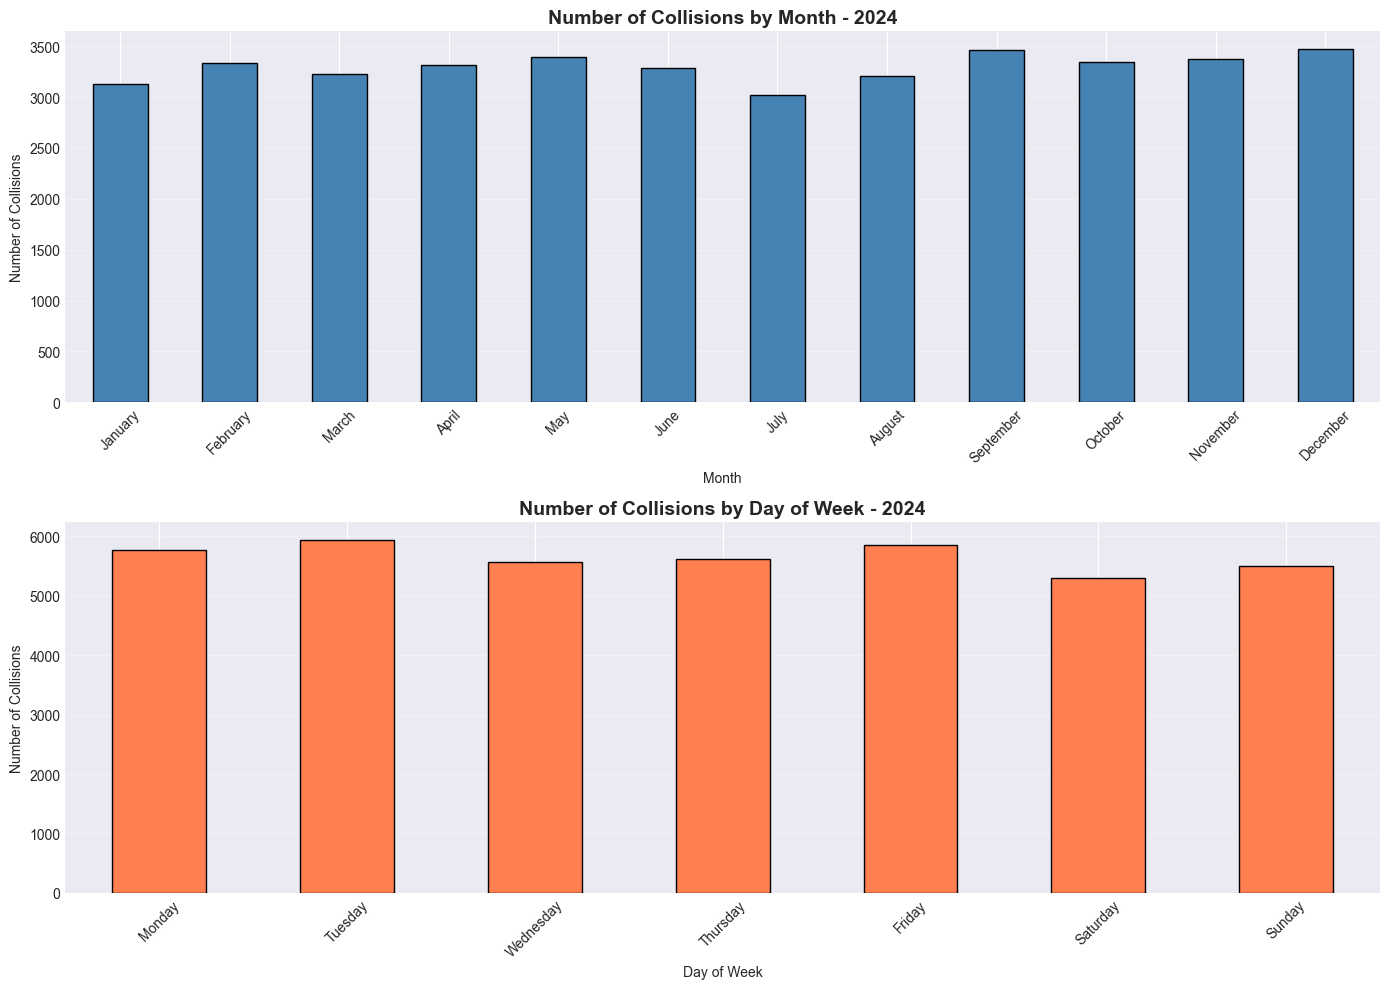

In [19]:
# Collisions over time (monthly)
if 'month_name' in collisions_clean.columns:
    fig, axes = plt.subplots(2, 1, figsize=(14, 10))
    
    # Monthly distribution
    month_order = ['January', 'February', 'March', 'April', 'May', 'June',
                   'July', 'August', 'September', 'October', 'November', 'December']
    monthly_collisions = collisions_clean['month_name'].value_counts().reindex(month_order)
    
    monthly_collisions.plot(kind='bar', ax=axes[0], color='steelblue', edgecolor='black')
    axes[0].set_title('Number of Collisions by Month - 2024', fontsize=14, fontweight='bold')
    axes[0].set_xlabel('Month')
    axes[0].set_ylabel('Number of Collisions')
    axes[0].tick_params(axis='x', rotation=45)
    axes[0].grid(axis='y', alpha=0.3)
    
    # Day of week distribution
    day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
    daily_collisions = collisions_clean['day_name'].value_counts().reindex(day_order)
    
    daily_collisions.plot(kind='bar', ax=axes[1], color='coral', edgecolor='black')
    axes[1].set_title('Number of Collisions by Day of Week - 2024', fontsize=14, fontweight='bold')
    axes[1].set_xlabel('Day of Week')
    axes[1].set_ylabel('Number of Collisions')
    axes[1].tick_params(axis='x', rotation=45)
    axes[1].grid(axis='y', alpha=0.3)
    
    plt.tight_layout()
    plt.show()

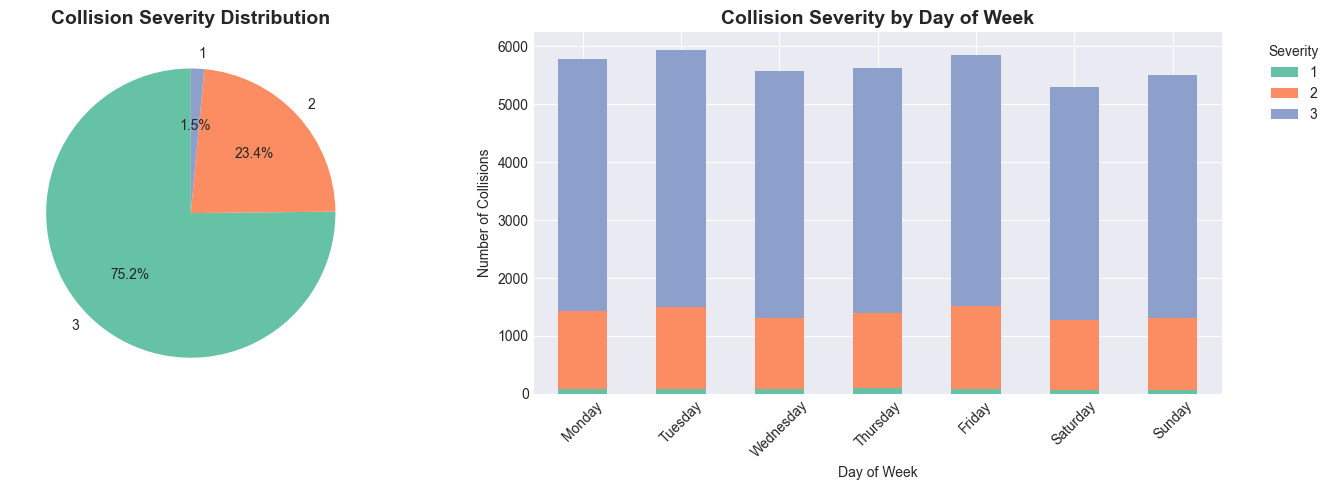

In [20]:
# Analyze severity (look for common column names)
severity_col = None
for col in collisions_clean.columns:
    if 'severity' in col.lower():
        severity_col = col
        break

if severity_col:
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    
    # Severity distribution pie chart
    severity_counts = collisions_clean[severity_col].value_counts()
    axes[0].pie(severity_counts.values, labels=severity_counts.index, autopct='%1.1f%%',
                startangle=90, colors=sns.color_palette('Set2'))
    axes[0].set_title('Collision Severity Distribution', fontsize=14, fontweight='bold')
    
    # Severity by day of week
    if 'day_name' in collisions_clean.columns:
        severity_by_day = pd.crosstab(collisions_clean['day_name'], 
                                       collisions_clean[severity_col])
        severity_by_day = severity_by_day.reindex(day_order)
        severity_by_day.plot(kind='bar', stacked=True, ax=axes[1], 
                            color=sns.color_palette('Set2'))
        axes[1].set_title('Collision Severity by Day of Week', fontsize=14, fontweight='bold')
        axes[1].set_xlabel('Day of Week')
        axes[1].set_ylabel('Number of Collisions')
        axes[1].tick_params(axis='x', rotation=45)
        axes[1].legend(title='Severity', bbox_to_anchor=(1.05, 1), loc='upper left')
    
    plt.tight_layout()
    plt.show()
else:
    print("Severity column not found in the dataset")

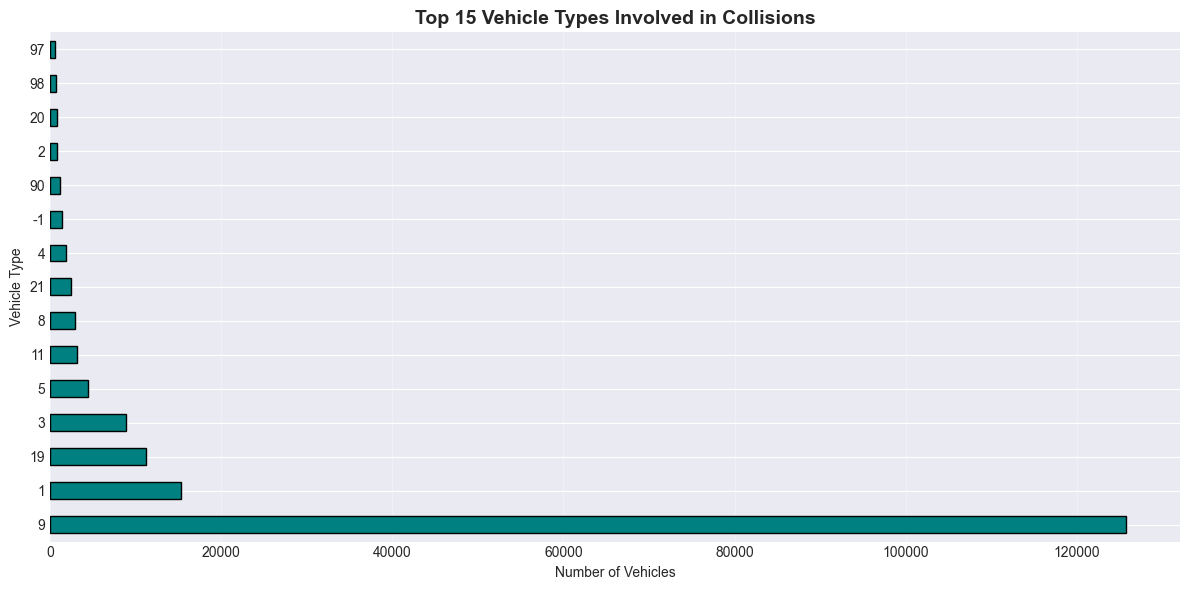

In [21]:
# Analyze vehicle types
vehicle_type_col = None
for col in vehicles_clean.columns:
    if 'vehicle_type' in col.lower() or 'type' in col.lower():
        vehicle_type_col = col
        break

if vehicle_type_col:
    fig, ax = plt.subplots(figsize=(12, 6))
    
    vehicle_counts = vehicles_clean[vehicle_type_col].value_counts().head(15)
    vehicle_counts.plot(kind='barh', ax=ax, color='teal', edgecolor='black')
    ax.set_title('Top 15 Vehicle Types Involved in Collisions', fontsize=14, fontweight='bold')
    ax.set_xlabel('Number of Vehicles')
    ax.set_ylabel('Vehicle Type')
    ax.grid(axis='x', alpha=0.3)
    
    plt.tight_layout()
    plt.show()
else:
    print("Vehicle type column not found in the dataset")

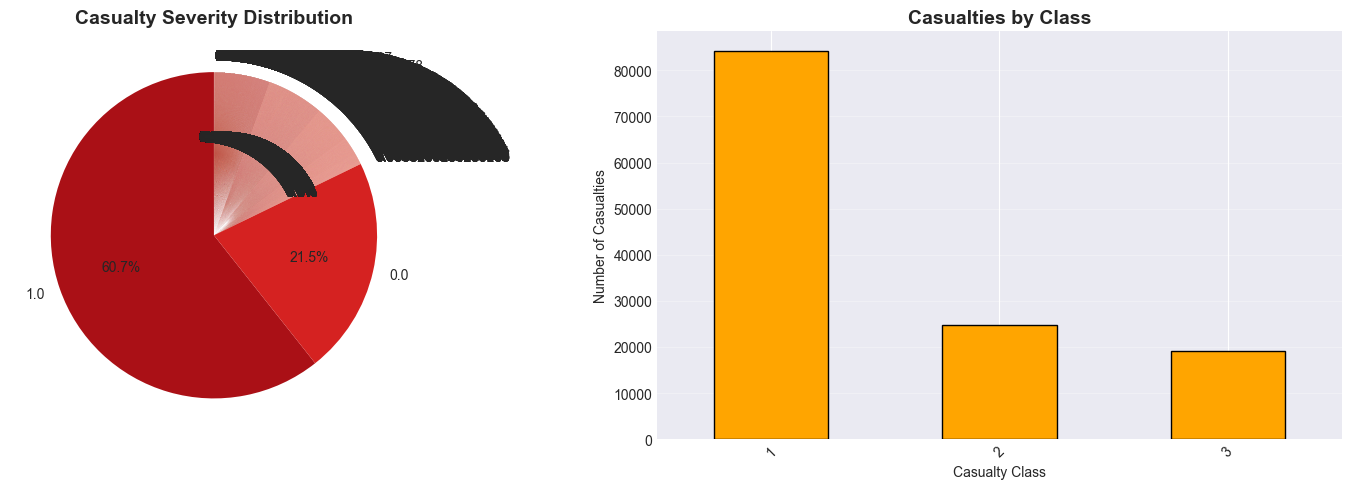

In [22]:
# Analyze casualties
casualty_severity_col = None
casualty_class_col = None

for col in casualties_clean.columns:
    if 'severity' in col.lower():
        casualty_severity_col = col
    if 'class' in col.lower():
        casualty_class_col = col

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Casualty severity
if casualty_severity_col:
    casualty_sev = casualties_clean[casualty_severity_col].value_counts()
    axes[0].pie(casualty_sev.values, labels=casualty_sev.index, autopct='%1.1f%%',
                startangle=90, colors=sns.color_palette('Reds_r'))
    axes[0].set_title('Casualty Severity Distribution', fontsize=14, fontweight='bold')
else:
    axes[0].text(0.5, 0.5, 'Casualty severity\ndata not found', 
                ha='center', va='center', fontsize=12)
    axes[0].axis('off')

# Casualty class (pedestrian, cyclist, etc.)
if casualty_class_col:
    casualty_class = casualties_clean[casualty_class_col].value_counts()
    casualty_class.plot(kind='bar', ax=axes[1], color='orange', edgecolor='black')
    axes[1].set_title('Casualties by Class', fontsize=14, fontweight='bold')
    axes[1].set_xlabel('Casualty Class')
    axes[1].set_ylabel('Number of Casualties')
    axes[1].tick_params(axis='x', rotation=45)
    axes[1].grid(axis='y', alpha=0.3)
else:
    axes[1].text(0.5, 0.5, 'Casualty class\ndata not found', 
                ha='center', va='center', fontsize=12)
    axes[1].axis('off')

plt.tight_layout()
plt.show()

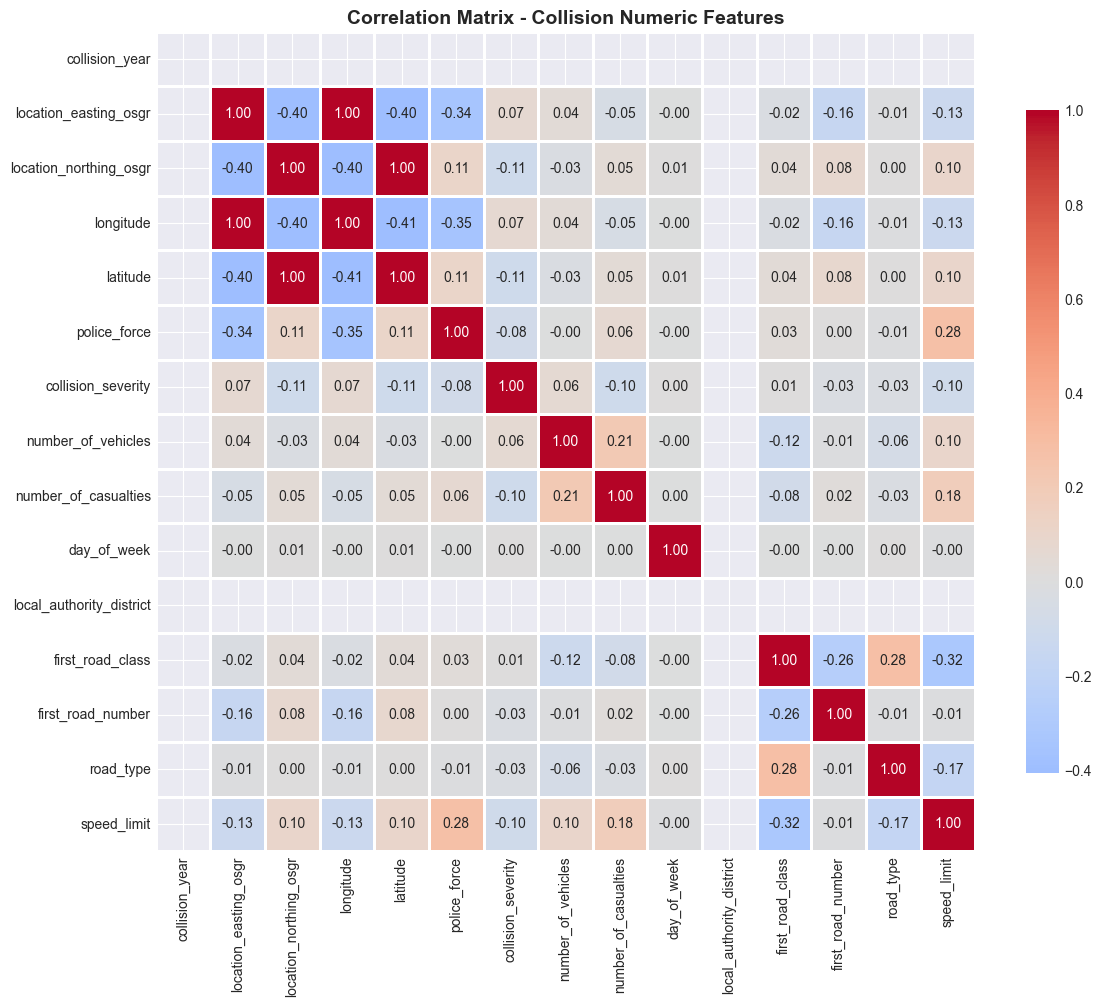

In [23]:
# Correlation heatmap for numeric columns in collisions
numeric_cols = collisions_clean.select_dtypes(include=[np.number]).columns.tolist()

if len(numeric_cols) > 1:
    # Select a subset of interesting numeric columns (max 15)
    cols_to_plot = numeric_cols[:15]
    
    correlation_matrix = collisions_clean[cols_to_plot].corr()
    
    plt.figure(figsize=(12, 10))
    sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', 
                center=0, square=True, linewidths=1, cbar_kws={"shrink": 0.8})
    plt.title('Correlation Matrix - Collision Numeric Features', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
else:
    print("Not enough numeric columns for correlation analysis")

In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from datetime import datetime, timedelta
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Statistical and time series libraries
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Configuration
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (14, 6)

print("✓ Libraries imported successfully!")
print("\nNote: If you get import errors for prophet, install it with:")
print("  pip install prophet")

✓ Libraries imported successfully!

Note: If you get import errors for prophet, install it with:
  pip install prophet


In [4]:
# Load collision data - UPDATE THIS PATH
collisions_path = 'collisions.csv'

print("Loading collision data...")
try:
    df = pd.read_csv(collisions_path, low_memory=False)
    print(f"✓ Data loaded successfully!")
    print(f"Shape: {df.shape}")
    print(f"\nFirst few columns: {df.columns.tolist()[:10]}")
except FileNotFoundError:
    print("Error: File not found. Please update the file path.")

Loading collision data...
✓ Data loaded successfully!
Shape: (100927, 44)

First few columns: ['collision_index', 'collision_year', 'collision_ref_no', 'location_easting_osgr', 'location_northing_osgr', 'longitude', 'latitude', 'police_force', 'collision_severity', 'number_of_vehicles']


In [5]:
# Display sample of data
print("Sample of raw data:")
display(df.head())

Sample of raw data:


,collision_index,collision_year,collision_ref_no,location_easting_osgr,location_northing_osgr,longitude,latitude,police_force,collision_severity,number_of_vehicles,number_of_casualties,date,day_of_week,time,local_authority_district,local_authority_ons_district,local_authority_highway,local_authority_highway_current,first_road_class,first_road_number,road_type,speed_limit,junction_detail_historic,junction_detail,junction_control,second_road_class,second_road_number,pedestrian_crossing_human_control_historic,pedestrian_crossing_physical_facilities_historic,pedestrian_crossing,light_conditions,weather_conditions,road_surface_conditions,special_conditions_at_site,carriageway_hazards_historic,carriageway_hazards,urban_or_rural_area,did_police_officer_attend_scene_of_accident,trunk_road_flag,lsoa_of_accident_location,enhanced_severity_collision,collision_injury_based,collision_adjusted_severity_serious,collision_adjusted_severity_slight
0,202417M119024,2024,17M119024,450057,519938,-1.22722,54.57219,17,3,2,1,05/12/2024,5,16:10,-1,E06000002,E06000002,E06000002,6,0,6,30,-1,0,-1,-1,-1,-1,-1,0,4,2,2,-1,-1,0,1,3,2,E01035190,3,1,0.000000,1.000000
1,202417S312124,2024,17S312124,445858,516830,-1.29265,54.54466,17,3,1,1,22/10/2024,3,14:56,-1,E06000004,E06000004,E06000004,6,0,6,30,-1,0,-1,-1,-1,-1,-1,0,1,1,1,-1,-1,0,1,3,2,E01012239,3,1,0.000000,1.000000
2,2024070110901,2024,070110901,364765,390979,-2.53157,53.41443,7,3,2,1,24/01/2024,4,17:50,-1,E06000007,E06000007,E06000007,6,0,6,30,3,13,4,6,0,0,0,0,4,1,1,0,0,0,2,2,2,E01012459,-1,0,0.014743,0.985257
3,2024041446676,2024,041446676,365989,419804,-2.51630,53.67359,4,2,1,1,22/05/2024,4,17:45,-1,E06000008,E06000008,E06000008,3,675,6,50,-1,0,-1,-1,-1,-1,-1,0,1,5,5,-1,-1,0,2,1,2,E01012628,6,1,1.000000,0.000000
4,2024041478641,2024,041478641,366864,430071,-2.50416,53.76592,4,2,2,1,11/08/2024,1,15:36,-1,E06000008,E06000008,E06000008,3,6119,3,50,-1,16,4,6,0,-1,-1,0,1,1,1,-1,-1,0,1,1,2,E01012581,7,1,1.000000,0.000000


In [6]:
# Find date column (common names in DfT data)
date_column = None
possible_date_cols = ['date', 'Date', 'accident_date', 'Accident_Date', 'collision_date']

for col in possible_date_cols:
    if col in df.columns:
        date_column = col
        break

if date_column is None:
    # Try to find any column with 'date' in the name
    date_cols = [col for col in df.columns if 'date' in col.lower()]
    if date_cols:
        date_column = date_cols[0]

print(f"Date column identified: {date_column}")

if date_column:
    # Convert to datetime
    df[date_column] = pd.to_datetime(df[date_column], errors='coerce')
    print(f"✓ Converted to datetime")
    print(f"\nDate range: {df[date_column].min()} to {df[date_column].max()}")
    print(f"Total days: {(df[date_column].max() - df[date_column].min()).days}")
else:
    print("\n⚠ Warning: Could not find date column automatically.")
    print("Please specify the date column manually.")

Date column identified: date
✓ Converted to datetime

Date range: 2024-01-01 00:00:00 to 2024-12-12 00:00:00
Total days: 346


In [7]:
# Create daily time series of collision counts
if date_column:
    # Daily counts
    daily_collisions = df.groupby(df[date_column].dt.date).size().reset_index()
    daily_collisions.columns = ['date', 'collision_count']
    daily_collisions['date'] = pd.to_datetime(daily_collisions['date'])
    daily_collisions = daily_collisions.set_index('date').sort_index()
    
    print("Daily Time Series Created:")
    print(f"Shape: {daily_collisions.shape}")
    print(f"\nFirst few rows:")
    display(daily_collisions.head(10))
    
    print(f"\nBasic Statistics:")
    display(daily_collisions.describe())

Daily Time Series Created:
Shape: (144, 1)

First few rows:


,collision_count
date,
2024-01-01,211
2024-01-02,281
2024-01-03,319
2024-01-04,194
2024-01-05,284
2024-01-06,273
2024-01-07,252
2024-01-08,279
2024-01-09,256



Basic Statistics:


,collision_count
count,144.000000
mean,274.798611
std,45.449977
min,142.000000
25%,246.000000
50%,276.000000
75%,303.500000
max,371.000000


In [8]:
# Create monthly time series (better for forecasting with limited data)
if date_column:
    # Monthly counts
    monthly_collisions = df.groupby(df[date_column].dt.to_period('M')).size().reset_index()
    monthly_collisions.columns = ['month', 'collision_count']
    monthly_collisions['month'] = monthly_collisions['month'].dt.to_timestamp()
    monthly_collisions = monthly_collisions.set_index('month').sort_index()
    
    print("Monthly Time Series Created:")
    print(f"Shape: {monthly_collisions.shape}")
    print(f"\nMonthly data:")
    display(monthly_collisions)
    
    print(f"\nBasic Statistics:")
    display(monthly_collisions.describe())

Monthly Time Series Created:
Shape: (12, 1)

Monthly data:


,collision_count
month,
2024-01-01,3131
2024-02-01,3337
2024-03-01,3229
2024-04-01,3320
2024-05-01,3392
2024-06-01,3285
2024-07-01,3020
2024-08-01,3205
2024-09-01,3466



Basic Statistics:


,collision_count
count,12.000000
mean,3297.583333
std,133.365157
min,3020.000000
25%,3223.000000
50%,3328.500000
75%,3375.500000
max,3473.000000


In [9]:
# Create weekly time series (good middle ground)
if date_column:
    # Weekly counts
    weekly_collisions = df.groupby(df[date_column].dt.to_period('W')).size().reset_index()
    weekly_collisions.columns = ['week', 'collision_count']
    weekly_collisions['week'] = weekly_collisions['week'].dt.to_timestamp()
    weekly_collisions = weekly_collisions.set_index('week').sort_index()
    
    print("Weekly Time Series Created:")
    print(f"Shape: {weekly_collisions.shape}")
    print(f"\nFirst few weeks:")
    display(weekly_collisions.head(10))

Weekly Time Series Created:
Shape: (31, 1)

First few weeks:


,collision_count
week,
2024-01-01,1814
2024-01-08,1317
2024-01-29,1027
2024-02-05,1991
2024-02-12,319
2024-02-26,734
2024-03-04,1936
2024-03-11,559
2024-04-01,1902


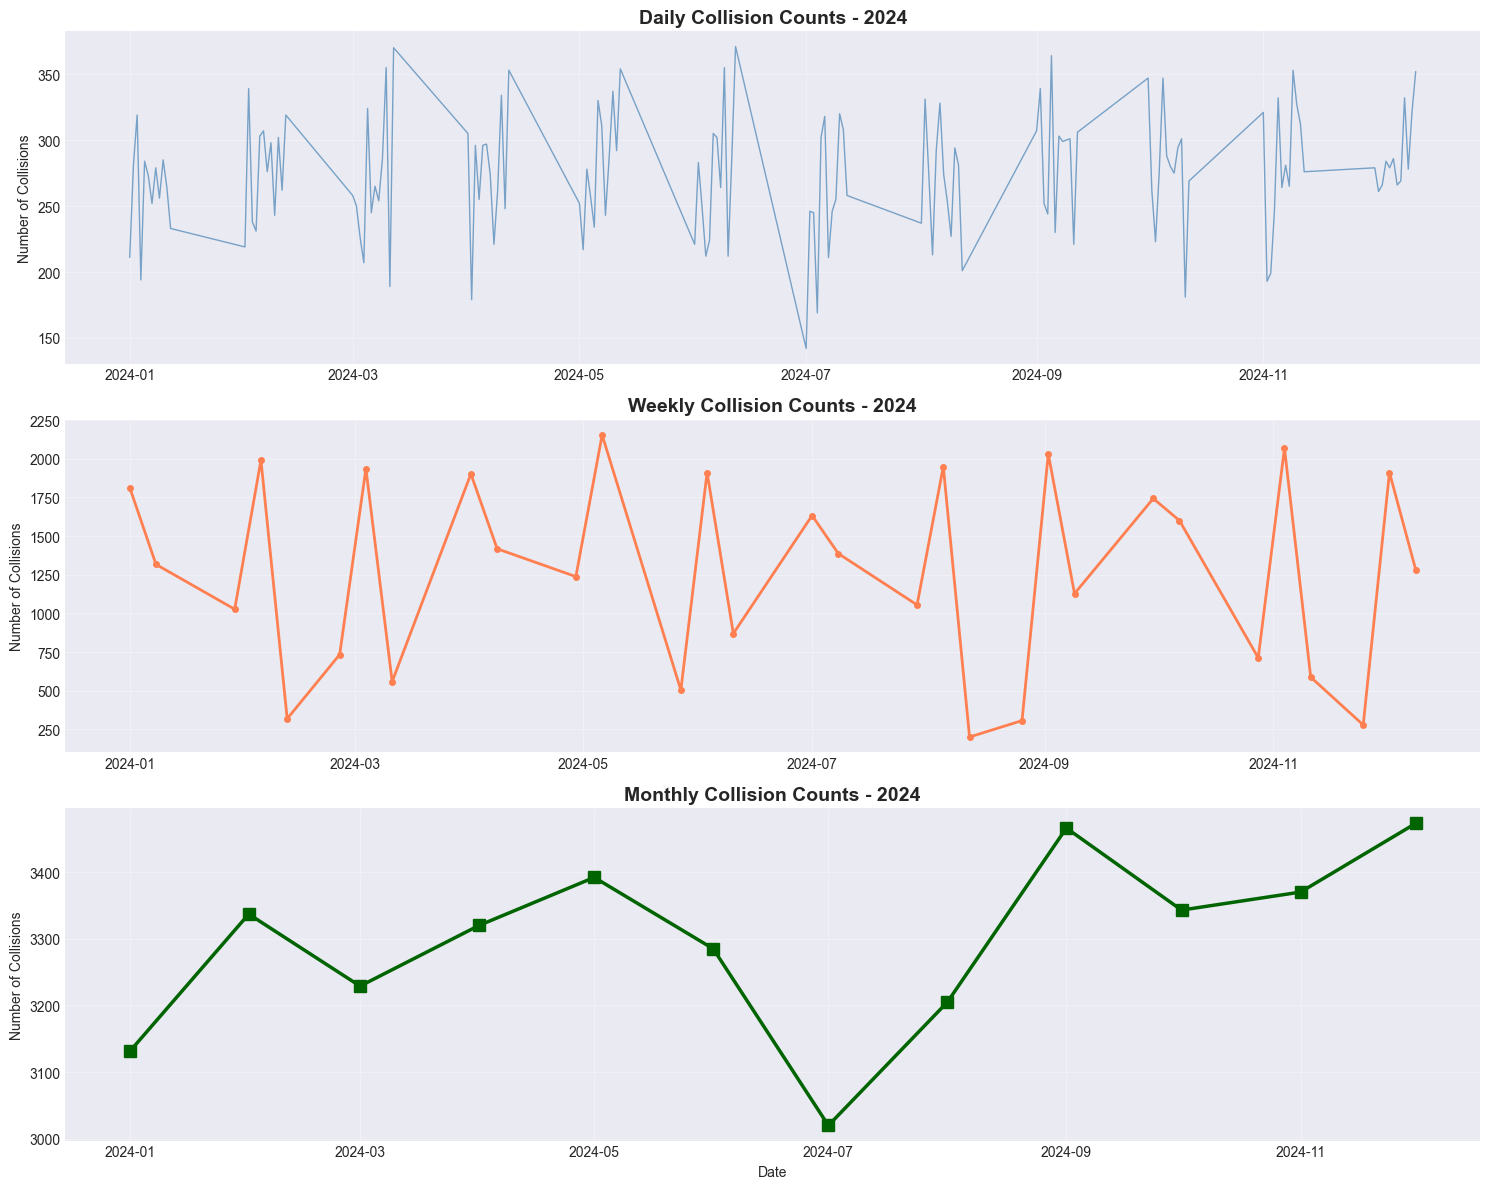

In [10]:
# Plot all time series together
fig, axes = plt.subplots(3, 1, figsize=(15, 12))

# Daily
axes[0].plot(daily_collisions.index, daily_collisions['collision_count'], 
             linewidth=1, alpha=0.7, color='steelblue')
axes[0].set_title('Daily Collision Counts - 2024', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Number of Collisions')
axes[0].grid(True, alpha=0.3)

# Weekly
axes[1].plot(weekly_collisions.index, weekly_collisions['collision_count'], 
             linewidth=2, color='coral', marker='o', markersize=4)
axes[1].set_title('Weekly Collision Counts - 2024', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Number of Collisions')
axes[1].grid(True, alpha=0.3)

# Monthly
axes[2].plot(monthly_collisions.index, monthly_collisions['collision_count'], 
             linewidth=2.5, color='darkgreen', marker='s', markersize=8)
axes[2].set_title('Monthly Collision Counts - 2024', fontsize=14, fontweight='bold')
axes[2].set_xlabel('Date')
axes[2].set_ylabel('Number of Collisions')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [11]:
# Decompose weekly time series (good balance for analysis)
if len(weekly_collisions) >= 52:  # Need at least 1 year of weekly data
    decomposition = seasonal_decompose(weekly_collisions['collision_count'], 
                                       model='additive', 
                                       period=52)  # 52 weeks in a year
    
    fig, axes = plt.subplots(4, 1, figsize=(15, 12))
    
    decomposition.observed.plot(ax=axes[0], color='steelblue')
    axes[0].set_ylabel('Observed')
    axes[0].set_title('Time Series Decomposition - Weekly Collisions', fontsize=14, fontweight='bold')
    axes[0].grid(True, alpha=0.3)
    
    decomposition.trend.plot(ax=axes[1], color='coral')
    axes[1].set_ylabel('Trend')
    axes[1].grid(True, alpha=0.3)
    
    decomposition.seasonal.plot(ax=axes[2], color='green')
    axes[2].set_ylabel('Seasonal')
    axes[2].grid(True, alpha=0.3)
    
    decomposition.resid.plot(ax=axes[3], color='red')
    axes[3].set_ylabel('Residual')
    axes[3].set_xlabel('Date')
    axes[3].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
else:
    print("Not enough data for seasonal decomposition (need at least 52 weeks)")
    print(f"Current weekly data points: {len(weekly_collisions)}")

Not enough data for seasonal decomposition (need at least 52 weeks)
Current weekly data points: 31


In [12]:
# Augmented Dickey-Fuller test for stationarity
def test_stationarity(timeseries, title):
    """
    Perform Augmented Dickey-Fuller test
    """
    print(f"\n{'='*60}")
    print(f"Stationarity Test: {title}")
    print(f"{'='*60}")
    
    # Perform ADF test
    result = adfuller(timeseries.dropna(), autolag='AIC')
    
    print(f"\nADF Statistic: {result[0]:.6f}")
    print(f"p-value: {result[1]:.6f}")
    print(f"Critical Values:")
    for key, value in result[4].items():
        print(f"  {key}: {value:.3f}")
    
    # Interpretation
    if result[1] <= 0.05:
        print(f"\n✓ Result: Series is STATIONARY (p-value <= 0.05)")
        print("  The series does not have a unit root and is suitable for modeling.")
    else:
        print(f"\n✗ Result: Series is NON-STATIONARY (p-value > 0.05)")
        print("  The series has a unit root and may need differencing.")

# Test on different time series
test_stationarity(daily_collisions['collision_count'], "Daily Collisions")
test_stationarity(weekly_collisions['collision_count'], "Weekly Collisions")
test_stationarity(monthly_collisions['collision_count'], "Monthly Collisions")


Stationarity Test: Daily Collisions

ADF Statistic: -2.678271
p-value: 0.077874
Critical Values:
  1%: -3.481
  5%: -2.884
  10%: -2.579

✗ Result: Series is NON-STATIONARY (p-value > 0.05)
  The series has a unit root and may need differencing.

Stationarity Test: Weekly Collisions

ADF Statistic: -4.247214
p-value: 0.000548
Critical Values:
  1%: -3.700
  5%: -2.976
  10%: -2.628

✓ Result: Series is STATIONARY (p-value <= 0.05)
  The series does not have a unit root and is suitable for modeling.

Stationarity Test: Monthly Collisions

ADF Statistic: -117.856125
p-value: 0.000000
Critical Values:
  1%: -4.939
  5%: -3.478
  10%: -2.844

✓ Result: Series is STATIONARY (p-value <= 0.05)
  The series does not have a unit root and is suitable for modeling.


ValueError: Can only compute partial correlations for lags up to 50% of the sample size. The requested nlags 20 must be < 15.

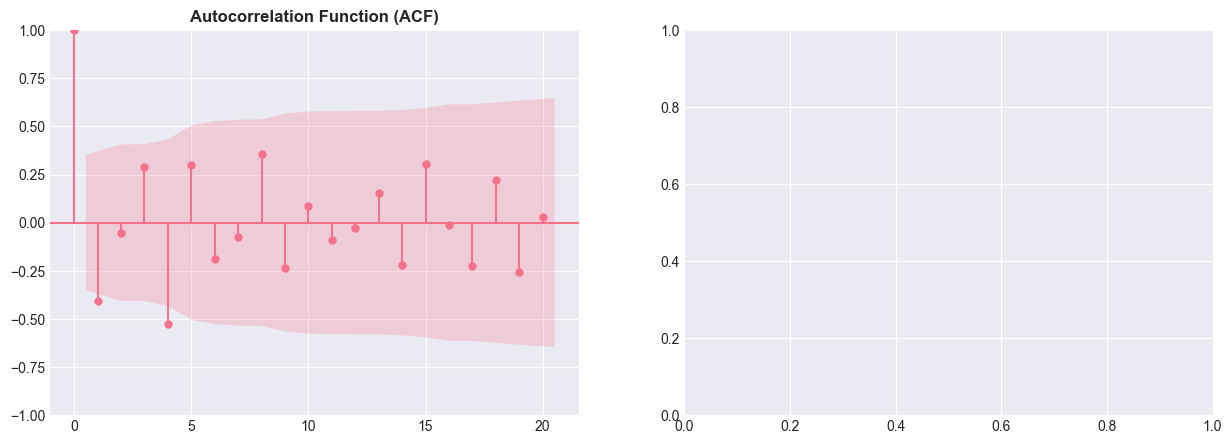

In [13]:
# Plot ACF and PACF for weekly data
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# ACF plot
plot_acf(weekly_collisions['collision_count'].dropna(), lags=20, ax=axes[0])
axes[0].set_title('Autocorrelation Function (ACF)', fontsize=12, fontweight='bold')

# PACF plot
plot_pacf(weekly_collisions['collision_count'].dropna(), lags=20, ax=axes[1])
axes[1].set_title('Partial Autocorrelation Function (PACF)', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

print("\nACF and PACF plots help identify:")
print("  • ACF: Shows correlation between observations at different lags")
print("  • PACF: Shows direct correlation after removing effects of intermediate lags")
print("  • These plots help determine ARIMA parameters (p, d, q)")

In [14]:
# Use monthly data for forecasting (more stable)
ts_data = monthly_collisions.copy()
ts_data['time_index'] = np.arange(len(ts_data))
ts_data['month_num'] = ts_data.index.month
ts_data['year'] = ts_data.index.year

print("Prepared data for Linear Regression:")
display(ts_data.head(10))

print(f"\nTotal months of data: {len(ts_data)}")

Prepared data for Linear Regression:


,collision_count,time_index,month_num,year
month,,,,
2024-01-01,3131,0,1,2024
2024-02-01,3337,1,2,2024
2024-03-01,3229,2,3,2024
2024-04-01,3320,3,4,2024
2024-05-01,3392,4,5,2024
2024-06-01,3285,5,6,2024
2024-07-01,3020,6,7,2024
2024-08-01,3205,7,8,2024
2024-09-01,3466,8,9,2024



Total months of data: 12


In [15]:
# Create additional features
# Cyclical encoding for months (to capture seasonality)
ts_data['month_sin'] = np.sin(2 * np.pi * ts_data['month_num'] / 12)
ts_data['month_cos'] = np.cos(2 * np.pi * ts_data['month_num'] / 12)

# Quarter
ts_data['quarter'] = ts_data.index.quarter

print("Features created for modeling:")
print(ts_data.columns.tolist())
display(ts_data.head())

Features created for modeling:
['collision_count', 'time_index', 'month_num', 'year', 'month_sin', 'month_cos', 'quarter']


,collision_count,time_index,month_num,year,month_sin,month_cos,quarter
month,,,,,,,
2024-01-01,3131,0,1,2024,0.500000,8.660254e-01,1
2024-02-01,3337,1,2,2024,0.866025,5.000000e-01,1
2024-03-01,3229,2,3,2024,1.000000,6.123234e-17,1
2024-04-01,3320,3,4,2024,0.866025,-5.000000e-01,2
2024-05-01,3392,4,5,2024,0.500000,-8.660254e-01,2


In [16]:
# Split data - use last 3 months as test set
train_size = len(ts_data) - 3
train_data = ts_data.iloc[:train_size]
test_data = ts_data.iloc[train_size:]

print(f"Training set: {len(train_data)} months ({train_data.index[0]} to {train_data.index[-1]})")
print(f"Test set: {len(test_data)} months ({test_data.index[0]} to {test_data.index[-1]})")

# Prepare features and target
feature_cols = ['time_index', 'month_sin', 'month_cos', 'quarter']
X_train = train_data[feature_cols]
y_train = train_data['collision_count']
X_test = test_data[feature_cols]
y_test = test_data['collision_count']

Training set: 9 months (2024-01-01 00:00:00 to 2024-09-01 00:00:00)
Test set: 3 months (2024-10-01 00:00:00 to 2024-12-01 00:00:00)


In [17]:
# Train Linear Regression model
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

print("✓ Linear Regression model trained!")
print(f"\nModel coefficients:")
for feature, coef in zip(feature_cols, lr_model.coef_):
    print(f"  {feature}: {coef:.4f}")
print(f"\nIntercept: {lr_model.intercept_:.4f}")

✓ Linear Regression model trained!

Model coefficients:
  time_index: 140.6975
  month_sin: 293.6396
  month_cos: 161.7711
  quarter: -117.8451

Intercept: 2935.8597


In [18]:
# Predictions on test set
y_pred_test = lr_model.predict(X_test)

# Also get predictions for training set
y_pred_train = lr_model.predict(X_train)

# Calculate metrics
mae_test = mean_absolute_error(y_test, y_pred_test)
rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_test))
r2_test = r2_score(y_test, y_pred_test)
mape_test = np.mean(np.abs((y_test - y_pred_test) / y_test)) * 100

print("="*60)
print("LINEAR REGRESSION MODEL PERFORMANCE")
print("="*60)
print(f"\nTest Set Metrics:")
print(f"  MAE (Mean Absolute Error): {mae_test:.2f} collisions")
print(f"  RMSE (Root Mean Squared Error): {rmse_test:.2f} collisions")
print(f"  R² Score: {r2_test:.4f}")
print(f"  MAPE (Mean Absolute Percentage Error): {mape_test:.2f}%")

print(f"\nActual vs Predicted (Test Set):")
comparison = pd.DataFrame({
    'Month': test_data.index,
    'Actual': y_test.values,
    'Predicted': y_pred_test,
    'Error': y_test.values - y_pred_test,
    'Error_%': ((y_test.values - y_pred_test) / y_test.values * 100)
})
display(comparison)

LINEAR REGRESSION MODEL PERFORMANCE

Test Set Metrics:
  MAE (Mean Absolute Error): 470.00 collisions
  RMSE (Root Mean Squared Error): 510.55 collisions
  R² Score: -82.0791
  MAPE (Mean Absolute Percentage Error): 13.76%

Actual vs Predicted (Test Set):


,Month,Actual,Predicted,Error,Error_%
0,2024-10-01,3343,3557.342995,-214.342995,-6.411696
1,2024-11-01,3370,3864.732362,-494.732362,-14.680486
2,2024-12-01,3473,4173.922861,-700.922861,-20.182058


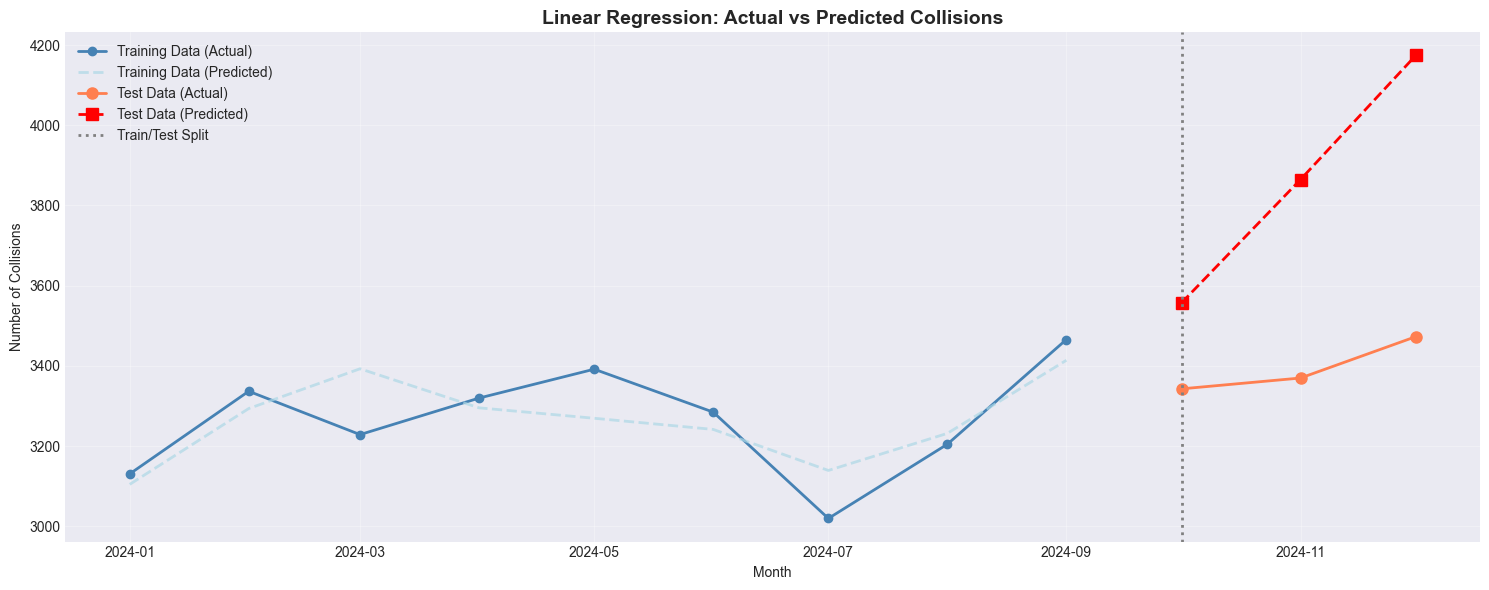

In [19]:
# Plot actual vs predicted
plt.figure(figsize=(15, 6))

# Plot training data
plt.plot(train_data.index, y_train, 'o-', label='Training Data (Actual)', 
         color='steelblue', linewidth=2, markersize=6)
plt.plot(train_data.index, y_pred_train, '--', label='Training Data (Predicted)', 
         color='lightblue', linewidth=2, alpha=0.7)

# Plot test data
plt.plot(test_data.index, y_test, 'o-', label='Test Data (Actual)', 
         color='coral', linewidth=2, markersize=8)
plt.plot(test_data.index, y_pred_test, 's--', label='Test Data (Predicted)', 
         color='red', linewidth=2, markersize=8)

plt.axvline(x=test_data.index[0], color='gray', linestyle=':', linewidth=2, label='Train/Test Split')

plt.title('Linear Regression: Actual vs Predicted Collisions', fontsize=14, fontweight='bold')
plt.xlabel('Month')
plt.ylabel('Number of Collisions')
plt.legend(loc='best')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [20]:
# Function to create future dates and features
def create_future_features(last_date, n_periods):
    """
    Create features for future periods
    """
    future_dates = pd.date_range(start=last_date + pd.DateOffset(months=1), 
                                 periods=n_periods, freq='MS')
    
    future_df = pd.DataFrame(index=future_dates)
    future_df['time_index'] = np.arange(len(ts_data), len(ts_data) + n_periods)
    future_df['month_num'] = future_df.index.month
    future_df['month_sin'] = np.sin(2 * np.pi * future_df['month_num'] / 12)
    future_df['month_cos'] = np.cos(2 * np.pi * future_df['month_num'] / 12)
    future_df['quarter'] = future_df.index.quarter
    
    return future_df

# Forecast next 12 months
future_months = 12
future_features = create_future_features(ts_data.index[-1], future_months)
X_future = future_features[feature_cols]
future_predictions = lr_model.predict(X_future)

print(f"\n{'='*60}")
print(f"FORECASTED COLLISIONS - NEXT {future_months} MONTHS")
print(f"{'='*60}\n")

forecast_df = pd.DataFrame({
    'Month': future_features.index.strftime('%Y-%m'),
    'Predicted_Collisions': future_predictions.astype(int)
})
display(forecast_df)

print(f"\nNext month forecast: {int(future_predictions[0])} collisions")
print(f"Total predicted for next year: {int(future_predictions.sum())} collisions")
print(f"Average per month (next year): {int(future_predictions.mean())} collisions")


FORECASTED COLLISIONS - NEXT 12 MONTHS



,Month,Predicted_Collisions
0,2025-01,4793
1,2025-02,4982
2,2025-03,5081
3,2025-04,4984
4,2025-05,4958
5,2025-06,4930
6,2025-07,4827
7,2025-08,4920
8,2025-09,5102
9,2025-10,5245



Next month forecast: 4793 collisions
Total predicted for next year: 61241 collisions
Average per month (next year): 5103 collisions


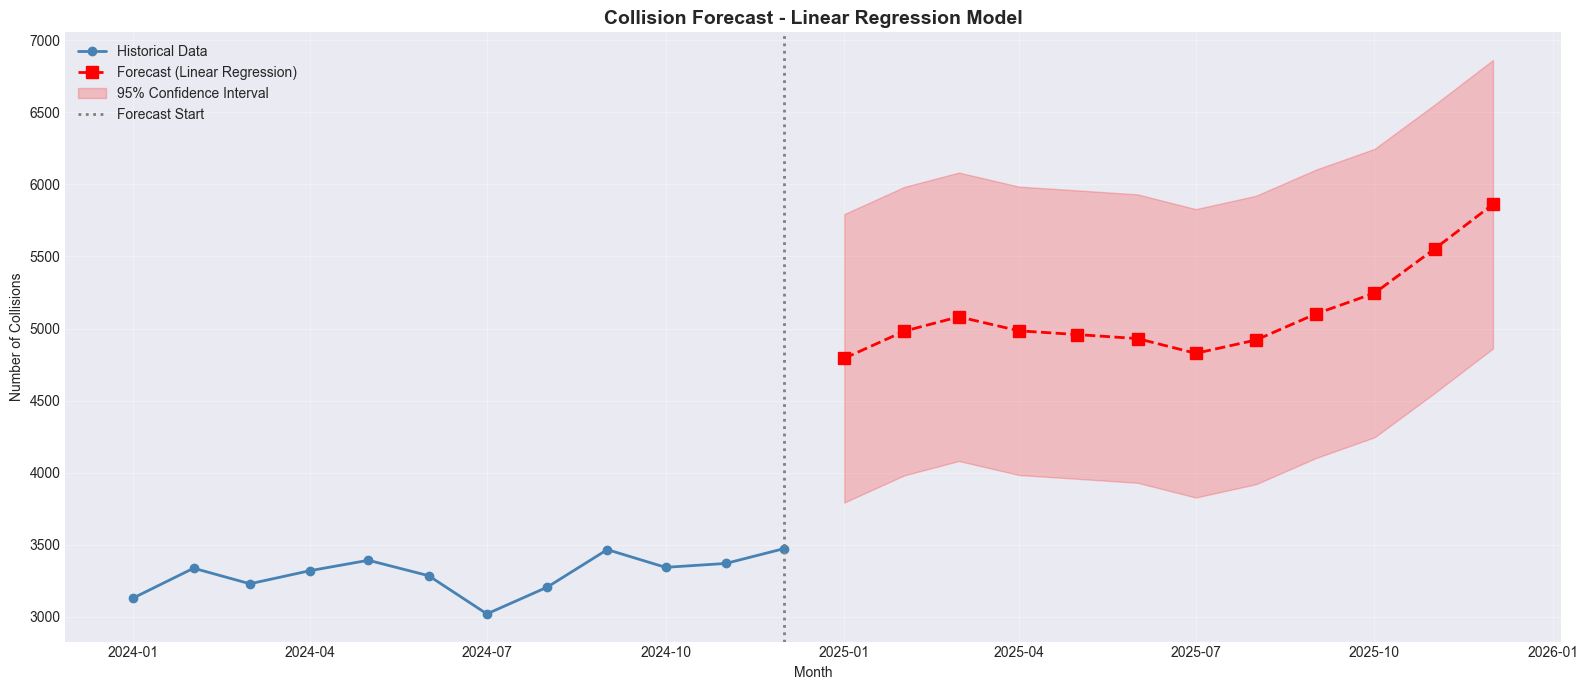

In [21]:
# Visualize forecast
plt.figure(figsize=(16, 7))

# Historical data
plt.plot(ts_data.index, ts_data['collision_count'], 'o-', 
         label='Historical Data', color='steelblue', linewidth=2, markersize=6)

# Future forecast
plt.plot(future_features.index, future_predictions, 's--', 
         label='Forecast (Linear Regression)', color='red', linewidth=2, markersize=8)

# Confidence interval (simple approximation using RMSE)
confidence = 1.96 * rmse_test  # 95% confidence interval
plt.fill_between(future_features.index, 
                 future_predictions - confidence, 
                 future_predictions + confidence,
                 alpha=0.2, color='red', label='95% Confidence Interval')

plt.axvline(x=ts_data.index[-1], color='gray', linestyle=':', linewidth=2, 
            label='Forecast Start')

plt.title('Collision Forecast - Linear Regression Model', fontsize=14, fontweight='bold')
plt.xlabel('Month')
plt.ylabel('Number of Collisions')
plt.legend(loc='best')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [22]:
# Simple Moving Average
window_size = 3
ts_data['MA'] = ts_data['collision_count'].rolling(window=window_size).mean()

# Forecast using last moving average value
ma_forecast = ts_data['MA'].iloc[-1]
ma_predictions = np.full(future_months, ma_forecast)

print(f"Moving Average Forecast (window={window_size}):")
print(f"  Predicted collisions per month: {int(ma_forecast)}")
print(f"  Total for next year: {int(ma_forecast * 12)}")

# Calculate error on test set
ma_test_pred = ts_data['MA'].iloc[train_size:train_size+len(test_data)].values
ma_mae = mean_absolute_error(y_test, ma_test_pred)
print(f"\nTest Set MAE: {ma_mae:.2f} collisions")

Moving Average Forecast (window=3):
  Predicted collisions per month: 3395
  Total for next year: 40744

Test Set MAE: 35.22 collisions


In [23]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

# Train Exponential Smoothing model
es_model = ExponentialSmoothing(
    train_data['collision_count'],
    seasonal_periods=12,
    trend='add',
    seasonal='add'
)
es_fit = es_model.fit()

# Forecast
es_predictions = es_fit.forecast(steps=future_months)
es_test_pred = es_fit.forecast(steps=len(test_data))

# Calculate metrics
es_mae = mean_absolute_error(y_test, es_test_pred)
es_rmse = np.sqrt(mean_squared_error(y_test, es_test_pred))

print("="*60)
print("EXPONENTIAL SMOOTHING MODEL PERFORMANCE")
print("="*60)
print(f"\nTest Set Metrics:")
print(f"  MAE: {es_mae:.2f} collisions")
print(f"  RMSE: {es_rmse:.2f} collisions")

print(f"\nNext 12 Months Forecast:")
es_forecast_df = pd.DataFrame({
    'Month': future_features.index.strftime('%Y-%m'),
    'Predicted_Collisions': es_predictions.values.astype(int)
})
display(es_forecast_df)

print(f"\nNext month forecast: {int(es_predictions.iloc[0])} collisions")
print(f"Total predicted for next year: {int(es_predictions.sum())} collisions")

ValueError: Cannot compute initial seasonals using heuristic method with less than two full seasonal cycles in the data.

In [24]:
# Train SARIMA model
# Parameters (p,d,q) x (P,D,Q,s)
# s=12 for monthly seasonality

print("Training SARIMA model...")
print("This may take a minute...\n")

try:
    sarima_model = SARIMAX(
        train_data['collision_count'],
        order=(1, 1, 1),  # (p,d,q)
        seasonal_order=(1, 1, 1, 12),  # (P,D,Q,s)
        enforce_stationarity=False,
        enforce_invertibility=False
    )
    sarima_fit = sarima_model.fit(disp=False)
    
    # Forecast
    sarima_predictions = sarima_fit.forecast(steps=future_months)
    sarima_test_pred = sarima_fit.forecast(steps=len(test_data))
    
    # Calculate metrics
    sarima_mae = mean_absolute_error(y_test, sarima_test_pred)
    sarima_rmse = np.sqrt(mean_squared_error(y_test, sarima_test_pred))
    
    print("="*60)
    print("SARIMA MODEL PERFORMANCE")
    print("="*60)
    print(f"\nTest Set Metrics:")
    print(f"  MAE: {sarima_mae:.2f} collisions")
    print(f"  RMSE: {sarima_rmse:.2f} collisions")
    
    print(f"\nNext 12 Months Forecast:")
    sarima_forecast_df = pd.DataFrame({
        'Month': future_features.index.strftime('%Y-%m'),
        'Predicted_Collisions': sarima_predictions.values.astype(int)
    })
    display(sarima_forecast_df)
    
    print(f"\nNext month forecast: {int(sarima_predictions.iloc[0])} collisions")
    print(f"Total predicted for next year: {int(sarima_predictions.sum())} collisions")
    
except Exception as e:
    print(f"Error training SARIMA model: {e}")
    print("This may happen with limited data. Try adjusting parameters or use other models.")

Training SARIMA model...
This may take a minute...

SARIMA MODEL PERFORMANCE

Test Set Metrics:
  MAE: 75.33 collisions
  RMSE: 90.17 collisions

Next 12 Months Forecast:


,Month,Predicted_Collisions
0,2025-01,3466
1,2025-02,3466
2,2025-03,3466
3,2025-04,5553
4,2025-05,5759
5,2025-06,5651
6,2025-07,5742
7,2025-08,5814
8,2025-09,5707
9,2025-10,5442



Next month forecast: 3466 collisions
Total predicted for next year: 61584 collisions


In [25]:
# Compare all models
comparison_results = pd.DataFrame({
    'Model': ['Linear Regression', 'Moving Average', 'Exponential Smoothing', 'SARIMA'],
    'MAE': [mae_test, ma_mae, es_mae, sarima_mae if 'sarima_mae' in locals() else np.nan],
    'RMSE': [rmse_test, np.nan, es_rmse, sarima_rmse if 'sarima_rmse' in locals() else np.nan],
    'Next_Month_Forecast': [
        int(future_predictions[0]),
        int(ma_forecast),
        int(es_predictions.iloc[0]),
        int(sarima_predictions.iloc[0]) if 'sarima_predictions' in locals() else np.nan
    ],
    'Next_Year_Total': [
        int(future_predictions.sum()),
        int(ma_forecast * 12),
        int(es_predictions.sum()),
        int(sarima_predictions.sum()) if 'sarima_predictions' in locals() else np.nan
    ]
})

print("="*80)
print("MODEL COMPARISON SUMMARY")
print("="*80)
display(comparison_results)

# Identify best model
best_model_idx = comparison_results['MAE'].idxmin()
best_model = comparison_results.loc[best_model_idx, 'Model']
print(f"\n✓ Best Model (Lowest MAE): {best_model}")
print(f"  MAE: {comparison_results.loc[best_model_idx, 'MAE']:.2f} collisions")

NameError: name 'es_mae' is not defined